In [3]:
# ---------------------------------------------------------------------
# 0. Import Libraries
# ---------------------------------------------------------------------
import sys
import os
import warnings
import numpy
import scipy
import matplotlib
import sklearn
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import least_squares, minimize
from scipy.spatial.distance import pdist
from scipy.stats import rankdata, norm, spearmanr, qmc
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, ConstantKernel as C

warnings.filterwarnings("ignore")
SEED = 42

print("=" * 100)
print("Software and Libraries used")
print("=" * 100)
print(f"  python      : {sys.version.split()[0]}")
print(f"  numpy       : {np.__version__}")
print(f"  scipy       : {scipy.__version__}")
print(f"  scikit-learn: {sklearn.__version__}")
print(f"  matplotlib  : {matplotlib.__version__}")
print(f"  SEED        : {SEED}")
print()

# Figures Colors and settings
SURFACE, INK, INK2, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e6e5e1"
BLUE, ORANGE, AQUA, RED = "#2a78d6", "#eb6834", "#1baf7a", "#e34948"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 10, "text.color": INK, "axes.edgecolor": MUTED, "axes.labelcolor": INK2,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

Software and Libraries used
  python      : 3.13.9
  numpy       : 2.3.5
  scipy       : 1.16.3
  scikit-learn: 1.9.0
  matplotlib  : 3.11.1
  SEED        : 42



n = 21, best row = 20, best y = 1.80382, previous best = 5.418e-08


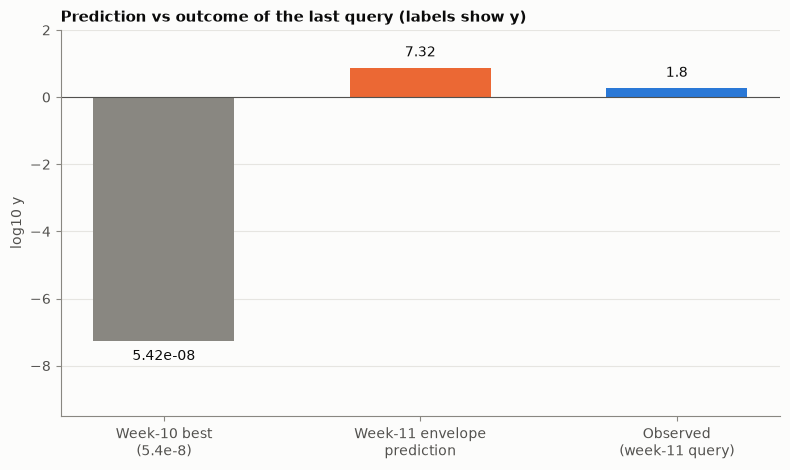

In [ ]:
# ---------------------------------------------------------------------
# 1. Load the data
# ---------------------------------------------------------------------
X = np.load('..\Function_1_Data\Week_12_Data/F1_Week_12_inputs.npy')
y = np.load('..\Function_1_Data\Week_12_Data/F1_Week_12_outputs.npy')
n = len(y)
N_INITIAL = 10
NEW = n - 1              
inc = int(np.argmax(y))
L = np.log10(np.abs(y))
print(f"n = {n}, best row = {inc}, best y = {y[inc]:.6g}, previous best = {np.max(y[:NEW]):.4g}")
#print(f"gain over previous best: x{y[inc] / np.max(y[:NEW]):.3g} ({np.log10(y[inc] / np.max(y[:NEW])):.1f} decades

# Fig 1: week-11 prediction vs outcome
fig, ax = plt.subplots(figsize=(8, 4.8))
pred_names = ["Week-10 best\n(5.4e-8)", "Week-11 envelope\nprediction", "Observed\n(week-11 query)"]
pred_vals = [L[NEW - 1], env(p_old, X[NEW:NEW + 1])[0], L[NEW]]
cols = [MUTED, ORANGE, BLUE]
bars = ax.bar(pred_names, pred_vals, color=cols, width=0.55)
ax.axhline(0, color=INK2, lw=0.8)
for b_, val in zip(bars, pred_vals):
    ax.text(b_.get_x() + b_.get_width() / 2, val + (0.25 if val >= 0 else -0.25), f"{10 ** val:.3g}",
            ha="center", va="bottom" if val >= 0 else "top", fontsize=10, color=INK)
ax.set_ylabel("log10 y"); ax.set_ylim(-9.5, 2)
ax.set_title("Prediction vs outcome of the last query (labels show y)")
ax.grid(axis="x", visible=False)
fig.tight_layout()

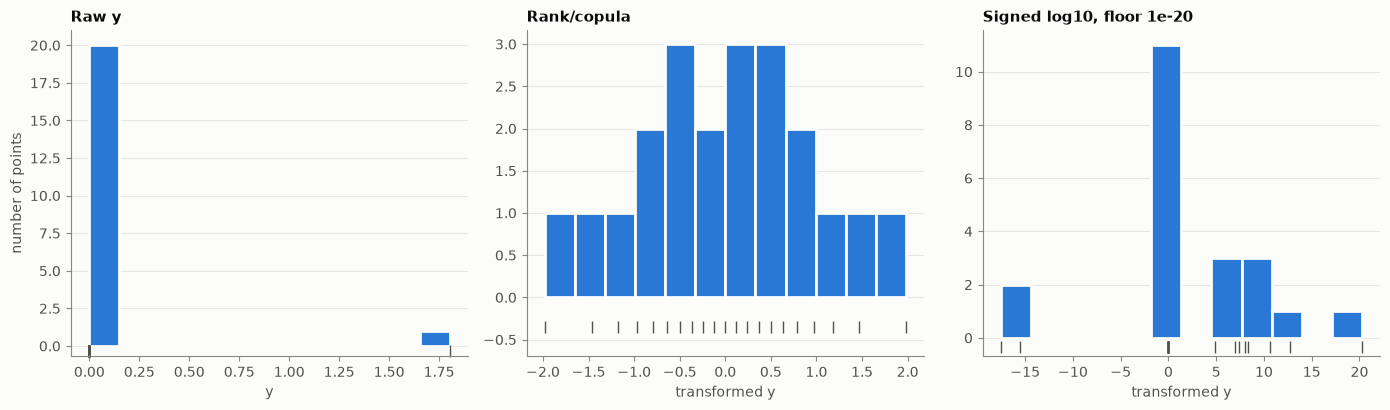

In [6]:
# ---------------------------------------------------------------------
# 2. Re-apply rank-based copula and signed log transforms to all points
# ---------------------------------------------------------------------
def copula(v):
    return norm.ppf((rankdata(v, method="average") - 0.5) / len(v))

FLOOR = -20.0
def signed_log(v):
    return np.sign(v) * np.maximum(np.log10(np.abs(v)) - FLOOR, 0.0)

targets = {"rank/copula": copula(y), "signed log10": signed_log(y)}

# Fig 2: target distributions
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, (title, vals, xl) in zip(axes, [("Raw y", y, "y"),
                                        ("Rank/copula", targets["rank/copula"], "transformed y"),
                                        ("Signed log10, floor 1e-20", targets["signed log10"], "transformed y")]):
    ax.hist(vals, bins=12, color=BLUE, edgecolor=SURFACE, linewidth=2)
    ax.plot(vals, np.full(n, -0.35), "|", color=INK2, markersize=9, clip_on=False)
    ax.set_title(title); ax.set_xlabel(xl); ax.set_ylim(bottom=-0.7); ax.grid(axis="x", visible=False)
axes[0].ticklabel_format(style="sci", axis="x", scilimits=(0, 0))
axes[0].set_ylabel("number of points")
fig.tight_layout()


SURROGATES (Matern 5/2, one length-scale per input, bounds 0.02-2.0)
  rank/copula  : length-scales x1=0.0330 x2=0.0211  LOO RMSE/std=0.922  Spearman=0.316  95% coverage=0.90
  signed log10 : length-scales x1=0.0294 x2=0.0206  LOO RMSE/std=0.945  Spearman=0.230  95% coverage=0.86
  rank/copula  : LOO for new row 20: actual +1.98, predicted -0.14 +/- 0.93
  signed log10 : LOO for new row 20: actual +20.26, predicted -1.09 +/- 7.99


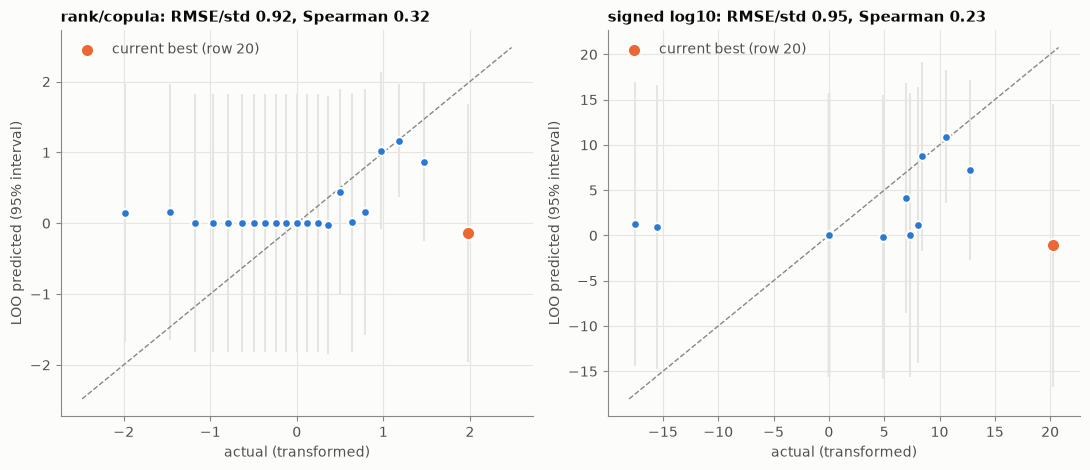

In [12]:
# ---------------------------------------------------------------------
# 3. Refit Matern 5/2 ARD GP on all points and perform LOO-CV
# ---------------------------------------------------------------------
def fit_gp(t):
    init = [np.median(pdist(X[:, [j]])) for j in range(2)]
    k = C(1.0, (1e-2, 1e2)) * Matern(length_scale=init, length_scale_bounds=(0.02, 2.0), nu=2.5)
    
    return GaussianProcessRegressor(kernel=k, alpha=1e-6, n_restarts_optimizer=15,
                                    random_state=SEED).fit(X, t)

def loo(gp, t):
    mu, sd = np.empty(n), np.empty(n)
    for i in range(n):
        keep = np.arange(n) != i
        g = GaussianProcessRegressor(kernel=gp.kernel_, alpha=1e-6, optimizer=None).fit(X[keep], t[keep])
        a, b = g.predict(X[i:i + 1], return_std=True)
        mu[i], sd[i] = a[0], b[0]
    return mu, sd

gps, loos = {}, {}
print("\nSURROGATES (Matern 5/2, one length-scale per input, bounds 0.02-2.0)")
for name, t in targets.items():
    gps[name] = fit_gp(t)
    loos[name] = loo(gps[name], t)
    mu, sd = loos[name]
    ls = gps[name].kernel_.k2.length_scale
    print(f"  {name:13s}: length-scales x1={ls[0]:.4f} x2={ls[1]:.4f}  "
          f"LOO RMSE/std={np.sqrt(np.mean((t - mu) ** 2)) / t.std():.3f}  "
          f"Spearman={spearmanr(t, mu)[0]:.3f}  "
          f"95% coverage={np.mean(np.abs((t - mu) / sd) < 1.96):.2f}")
# LOO prediction of the new point from the first 20 (what the GP said before the query)
for name, t in targets.items():
    print(f"  {name:13s}: LOO for new row {NEW}: actual {t[NEW]:+.2f}, predicted {loos[name][0][NEW]:+.2f} "
          f"+/- {loos[name][1][NEW]:.2f}")

# Fig 3: LOO CV
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
for ax, name in zip(axes, targets):
    t = targets[name]; mu, sd = loos[name]
    lim = [min(t.min(), mu.min()) - 0.5, max(t.max(), mu.max()) + 0.5]
    ax.plot(lim, lim, color=MUTED, lw=1, ls="--")
    ax.errorbar(t, mu, yerr=1.96 * sd, fmt="none", ecolor=GRID, elinewidth=1.5, zorder=1)
    ax.scatter(t, mu, s=40, color=BLUE, edgecolor=SURFACE, linewidth=1.5, zorder=3)
    ax.scatter(t[inc], mu[inc], s=90, color=ORANGE, edgecolor=SURFACE, linewidth=1.5, zorder=4,
               label="current best (row 20)")
    ax.set_title(f"{name}: RMSE/std {np.sqrt(np.mean((t - mu) ** 2)) / t.std():.2f}, "
                 f"Spearman {spearmanr(t, mu)[0]:.2f}")
    ax.set_xlabel("actual (transformed)"); ax.set_ylabel("LOO predicted (95% interval)")
    ax.legend(frameon=False, loc="upper left", labelcolor=INK2)
fig.tight_layout()


ENVELOPE MODELS  log10|y| = a - k*|x - c|^2
  week-11 fit (5 positive)
    a=0.865 k=741.6 centre=(0.623655, 0.632907) peak |y|~7.32 width=0.0171  rms resid=0.052 decades
    leave-one-out centres: x1 0.5865-0.6302, x2 0.5949-0.6638
  6 positive (adds new)
    a=0.325 k=712.1 centre=(0.623146, 0.632700) peak |y|~2.11 width=0.0175  rms resid=0.096 decades
    leave-one-out centres: x1 0.6000-0.6300, x2 0.6259-0.6526
  8 points (adds rows 4, 17 as |y|)
    a=0.205 k=710.8 centre=(0.629016, 0.626947) peak |y|~1.60 width=0.0175  rms resid=0.150 decades
    leave-one-out centres: x1 0.6254-0.6295, x2 0.6257-0.6283

Week-11 prediction at the queried point: log10 y = +0.865 (|y| ~ 7.32); observed log10 y = +0.256 (y = 1.804); error -0.61 decades
Centre shift 6-pos vs week-11: 0.0005; 8-pt vs week-11: 0.0080
  sign check around the 8-point centre (distance, sign, residual vs envelope):
    row 20  r = 0.0080  +  y = +1.804e+00  residual = +0.10 decades
    row  4  r = 0.0585  -  y = -3.606e-0

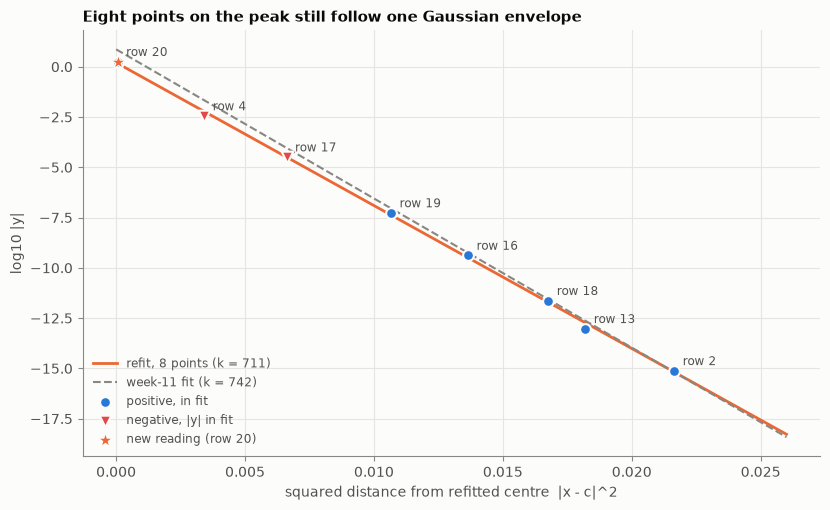

In [10]:
# ---------------------------------------------------------------------
# 4. Fit a Gaussian bump gives log10|y| = a - k * |x - c|^2 near the isolated peak.
# ---------------------------------------------------------------------
def env(p, Z):
    a, k, c1, c2 = p
    return a - k * ((Z[:, 0] - c1) ** 2 + (Z[:, 1] - c2) ** 2)

def fit_env(rows, x0=(0.0, 700, 0.62, 0.63)):
    p = least_squares(lambda q: env(q, X[rows]) - L[rows], x0).x
    jack = np.array([least_squares(lambda q, T=[j for j in rows if j != i]: env(q, X[T]) - L[T], x0).x for i in rows])
    return p, jack

ENV_OLD = [2, 13, 16, 18, 19]                  # week-11 fit set
ENV_POS = ENV_OLD + [NEW]                      # + new reading
ENV_ALL = ENV_POS + [4, 17]                    # + the two negative readings (|y|)
fits = {}
print("\nENVELOPE MODELS  log10|y| = a - k*|x - c|^2")
for name, rows in [("week-11 fit (5 positive)", ENV_OLD),
                   ("6 positive (adds new)", ENV_POS),
                   ("8 points (adds rows 4, 17 as |y|)", ENV_ALL)]:
    p, jack = fit_env(rows)
    fits[name] = (rows, p, jack)
    res = env(p, X[rows]) - L[rows]
    print(f"  {name}")
    print(f"    a={p[0]:.3f} k={p[1]:.1f} centre=({p[2]:.6f}, {p[3]:.6f}) peak |y|~{10 ** p[0]:.2f} "
          f"width={np.sqrt(np.log10(np.e) / (2 * p[1])):.4f}  rms resid={np.sqrt(np.mean(res ** 2)):.3f} decades")
    print(f"    leave-one-out centres: x1 {jack[:, 2].min():.4f}-{jack[:, 2].max():.4f}, "
          f"x2 {jack[:, 3].min():.4f}-{jack[:, 3].max():.4f}")

p_old = fits["week-11 fit (5 positive)"][1]
p_pos = fits["6 positive (adds new)"][1]
p_all = fits["8 points (adds rows 4, 17 as |y|)"][1]
print(f"\nWeek-11 prediction at the queried point: log10 y = {env(p_old, X[NEW:NEW+1])[0]:+.3f} "
      f"(|y| ~ {10 ** env(p_old, X[NEW:NEW+1])[0]:.2f}); observed log10 y = {L[NEW]:+.3f} (y = {y[NEW]:.3f}); "
      f"error {L[NEW] - env(p_old, X[NEW:NEW+1])[0]:+.2f} decades")

centre_pos, centre_all = p_pos[2:], p_all[2:]
print(f"Centre shift 6-pos vs week-11: {np.linalg.norm(centre_pos - p_old[2:]):.4f}; "
      f"8-pt vs week-11: {np.linalg.norm(centre_all - p_old[2:]):.4f}")

r_c = np.linalg.norm(X - centre_all, axis=1)
print("  sign check around the 8-point centre (distance, sign, residual vs envelope):")
for i in np.argsort(r_c):
    if r_c[i] < 0.15:
        print(f"    row {i:2d}  r = {r_c[i]:.4f}  {'+' if y[i] > 0 else '-'}  y = {y[i]:+.3e}  "
              f"residual = {L[i] - env(p_all, X[i:i+1])[0]:+.2f} decades")

# ---------------------------------------------------------------------
# Fig 4: envelope fit
# ---------------------------------------------------------------------
d2 = np.sum((X - centre_all) ** 2, axis=1)
fig, ax = plt.subplots(figsize=(8.4, 5.2))
grid = np.linspace(0, 0.026, 50)
ax.plot(grid, p_all[0] - p_all[1] * grid, color=ORANGE, lw=2, label=f"refit, 8 points (k = {p_all[1]:.0f})")
ax.plot(grid, p_old[0] - p_old[1] * grid, color=MUTED, lw=1.5, ls="--", label=f"week-11 fit (k = {p_old[1]:.0f})")
neg = [4, 17]
pos_fit = [i for i in ENV_ALL if i not in neg]
ax.scatter(d2[pos_fit], L[pos_fit], s=60, color=BLUE, edgecolor=SURFACE, linewidth=1.5, zorder=3, label="positive, in fit")
ax.scatter(d2[neg], L[neg], s=70, marker="v", color=RED, edgecolor=SURFACE, linewidth=1.5, zorder=3, label="negative, |y| in fit")
ax.scatter(d2[NEW], L[NEW], s=130, marker="*", color=ORANGE, edgecolor=SURFACE, linewidth=1, zorder=4, label="new reading (row 20)")
for i in ENV_ALL:
    ax.annotate(f"row {i}", (d2[i], L[i]), xytext=(6, 4), textcoords="offset points", fontsize=8.5, color=INK2)
ax.set_xlabel("squared distance from refitted centre  |x - c|^2")
ax.set_ylabel("log10 |y|")
ax.set_title("Eight points on the peak still follow one Gaussian envelope")
ax.legend(frameon=False, loc="lower left", labelcolor=INK2, fontsize=8.5)
fig.tight_layout()


GP-EI maximum EI = 0.09873

CANDIDATES
  A: GP-EI (copula, xi=0)          x = (0.618096, 0.625267)  dist to best = 0.0094  envelope log10 y: wk11 +0.80 | 6pos +0.27 | 8pt +0.12   GP copula +1.80 +/- 0.43
  B: 6-positive envelope centre    x = (0.623146, 0.632700)  dist to best = 0.0006  envelope log10 y: wk11 +0.86 | 6pos +0.32 | 8pt +0.16   GP copula +1.98 +/- 0.02
  C: 8-point envelope centre       x = (0.629016, 0.626947)  dist to best = 0.0080  envelope log10 y: wk11 +0.82 | 6pos +0.28 | 8pt +0.20   GP copula +1.85 +/- 0.37
  D: mean of the two centres       x = (0.626081, 0.629823)  dist to best = 0.0039  envelope log10 y: wk11 +0.85 | 6pos +0.31 | 8pt +0.19   GP copula +1.96 +/- 0.19
  reference: best observed log10 y = +0.256


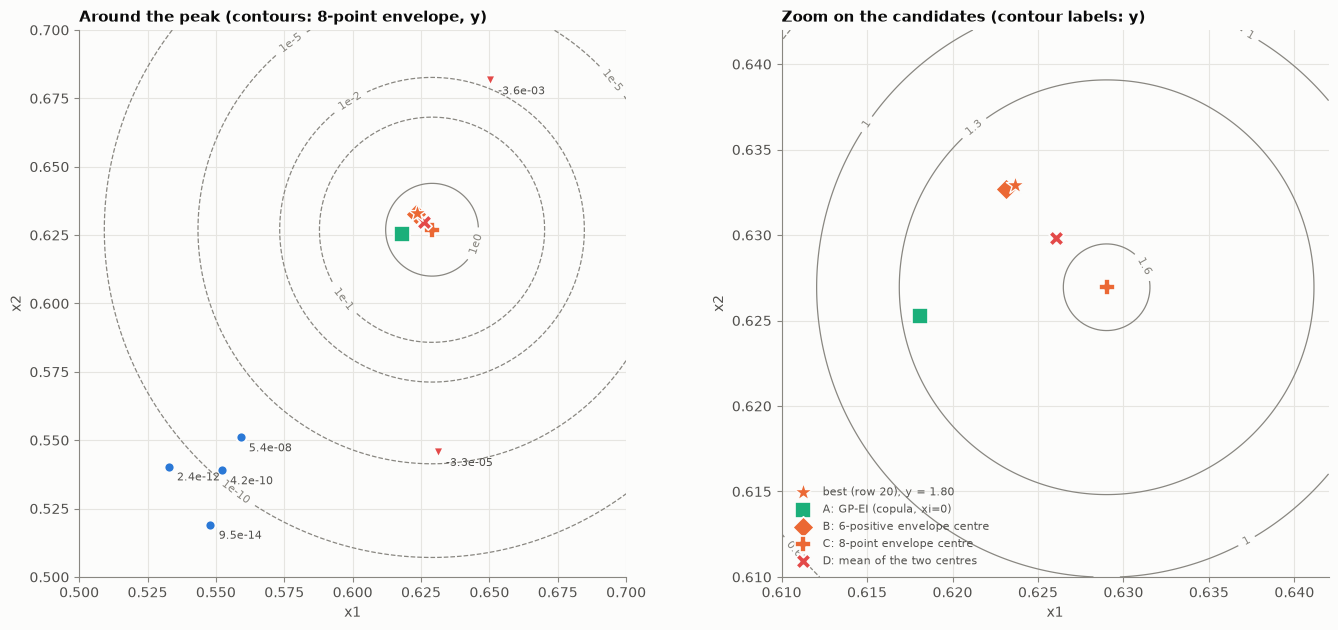

In [13]:
# ---------------------------------------------------------------- 
# Candidates
# ---------------------------------------------------------------------
gp_c = gps["rank/copula"]
f_best = targets["rank/copula"].max()
def ei(Z, xi=0.0):
    mu, s = gp_c.predict(Z, return_std=True)
    s = np.maximum(s, 1e-12)
    z = (mu - f_best - xi) / s
    return (mu - f_best - xi) * norm.cdf(z) + s * norm.pdf(z)

S = np.vstack([qmc.Sobol(2, seed=1).random(2 ** 14), X])
v = ei(S)
x_ei, best = S[v.argmax()], v.max()
for x0 in S[np.argsort(-v)[:15]]:
    r = minimize(lambda x: -ei(x[None])[0], x0, bounds=[(0, 1)] * 2, method="L-BFGS-B")
    if -r.fun > best:
        x_ei, best = r.x, -r.fun
print(f"\nGP-EI maximum EI = {best:.4g}")

cands = {
    "A: GP-EI (copula, xi=0)": x_ei,
    "B: 6-positive envelope centre": centre_pos,
    "C: 8-point envelope centre": centre_all,
    "D: mean of the two centres": 0.5 * (centre_pos + centre_all),
}
print("\nCANDIDATES")
rows_tbl = []
for name, xc in cands.items():
    e_old = env(p_old, xc[None])[0]; e_pos = env(p_pos, xc[None])[0]; e_all = env(p_all, xc[None])[0]
    mu_c, sd_c = gp_c.predict(xc[None], return_std=True)
    d = np.linalg.norm(xc - X[inc])
    print(f"  {name:32s} x = ({xc[0]:.6f}, {xc[1]:.6f})  dist to best = {d:.4f}  "
          f"envelope log10 y: wk11 {e_old:+.2f} | 6pos {e_pos:+.2f} | 8pt {e_all:+.2f}   "
          f"GP copula {mu_c[0]:+.2f} +/- {sd_c[0]:.2f}")
print(f"  reference: best observed log10 y = {L[inc]:+.3f}")

# ---------------------------------------------------------------------
# Fig 5: map with candidates (left: wide, right: zoom on the peak)
# ---------------------------------------------------------------------
marks = {"A: GP-EI (copula, xi=0)": ("s", AQUA), "B: 6-positive envelope centre": ("D", ORANGE),
         "C: 8-point envelope centre": ("P", ORANGE), "D: mean of the two centres": ("X", RED)}
fig, axes = plt.subplots(1, 2, figsize=(14, 6.4))
for ax, (lo, hi, levels, zoom) in zip(axes, [(0.50, 0.70, [-10, -5, -2, -1, 0], False),
                                              (0.610, 0.642, [-0.6, -0.4, -0.2, 0.0, 0.1, 0.2], True)]):
    g1 = np.linspace(lo, hi, 200)
    G1, G2 = np.meshgrid(g1, g1)
    E = env(p_all, np.column_stack([G1.ravel(), G2.ravel()])).reshape(G1.shape)
    cs = ax.contour(G1, G2, E, levels=levels, colors=MUTED, linewidths=0.9)
    ax.clabel(cs, fmt=(lambda v_: f"{10 ** v_:.2g}") if zoom else (lambda v_: f"1e{int(v_)}"), fontsize=8)
    if not zoom:
        inside = np.all((X >= lo) & (X <= hi), axis=1)
        for i in np.where(inside)[0]:
            col = RED if y[i] < 0 else BLUE
            ax.scatter(*X[i], s=55, color=col, edgecolor=SURFACE, linewidth=1.5, zorder=3,
                       marker="v" if y[i] < 0 else "o")
            if i != inc:
                ax.annotate(f"{y[i]:.1e}", X[i], xytext=(6, -10), textcoords="offset points", fontsize=8, color=INK2)
    ax.scatter(*X[inc], s=190, marker="*", color=ORANGE, edgecolor=SURFACE, linewidth=1, zorder=6,
               label="best (row 20), y = 1.80")
    for name, xc in cands.items():
        m, c = marks[name]
        ax.scatter(*xc, s=120, marker=m, color=c, edgecolor=SURFACE, linewidth=1.2, zorder=5, label=name)
    ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
    ax.set_aspect("equal"); ax.set_xlabel("x1"); ax.set_ylabel("x2")
axes[0].set_title("Around the peak (contours: 8-point envelope, y)")
axes[1].set_title("Zoom on the candidates (contour labels: y)")
axes[1].legend(frameon=False, loc="lower left", fontsize=8, labelcolor=INK2)
fig.tight_layout()

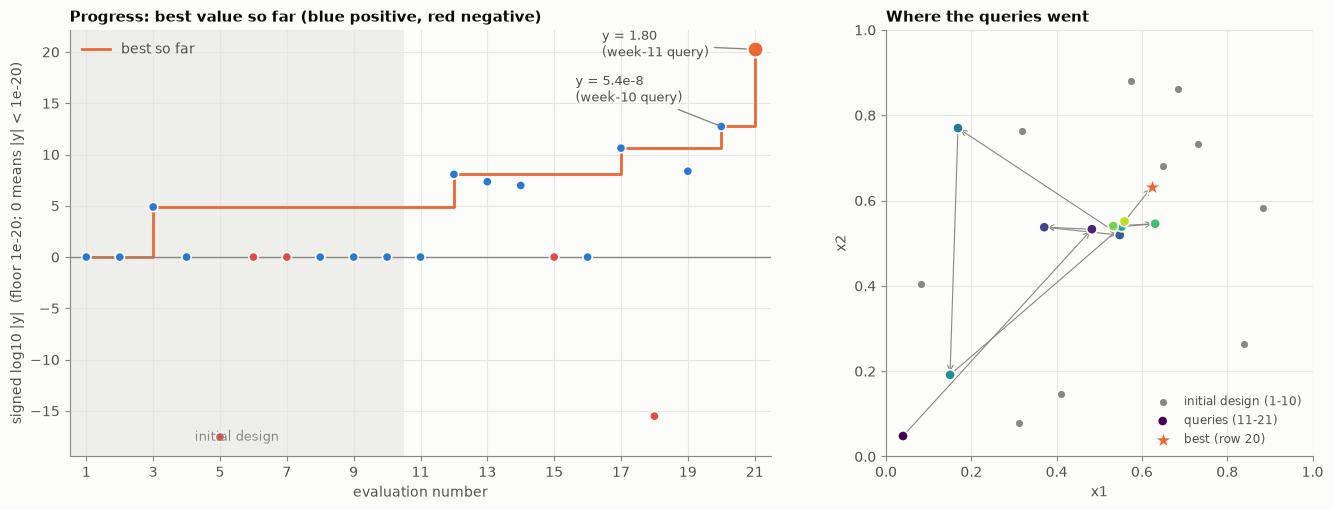

In [8]:
# ---------------------------------------------------------------------
# Fig 6: progress
# ---------------------------------------------------------------------
sl = signed_log(y)
best_sofar = np.maximum.accumulate(y)
bs_sl = signed_log(best_sofar)
idx = np.arange(1, n + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1.25, 1]})
ax = axes[0]
ax.axvspan(0.5, N_INITIAL + 0.5, color=GRID, alpha=0.6, lw=0)
ax.step(idx, bs_sl, where="post", color=ORANGE, lw=2, label="best so far")
colors = [RED if v_ < 0 else BLUE for v_ in y]
ax.scatter(idx, sl, c=colors, s=45, edgecolor=SURFACE, linewidth=1.2, zorder=3)
ax.scatter(idx[inc], sl[inc], s=130, color=ORANGE, edgecolor=SURFACE, linewidth=1.5, zorder=4)
ax.axhline(0, color=MUTED, lw=1)
ax.annotate(f"y = {y[inc]:.2f}\n(week-11 query)", (idx[inc], sl[inc]), xytext=(-110, -5),
            textcoords="offset points", fontsize=9, color=INK2, arrowprops=dict(arrowstyle="-", color=MUTED))
ax.annotate("y = 5.4e-8\n(week-10 query)", (idx[19], sl[19]), xytext=(-105, 18),
            textcoords="offset points", fontsize=9, color=INK2, arrowprops=dict(arrowstyle="-", color=MUTED))
ax.text(N_INITIAL / 2 + 0.5, 0.03, "initial design", ha="center", va="bottom",
        transform=ax.get_xaxis_transform(), fontsize=9, color=MUTED)
ax.set_xticks(idx[::2]); ax.set_xlim(0.5, n + 0.5)
ax.set_xlabel("evaluation number"); ax.set_ylabel("signed log10 |y|  (floor 1e-20; 0 means |y| < 1e-20)")
ax.set_title("Progress: best value so far (blue positive, red negative)")
ax.legend(frameon=False, loc="upper left", labelcolor=INK2)

ax = axes[1]
ax.scatter(X[:N_INITIAL, 0], X[:N_INITIAL, 1], s=40, color=MUTED, edgecolor=SURFACE, linewidth=1.2,
           zorder=3, label="initial design (1-10)")
q = np.arange(N_INITIAL, n)
sc = ax.scatter(X[q, 0], X[q, 1], s=55, c=np.arange(len(q)), cmap="viridis", edgecolor=SURFACE,
                linewidth=1.2, zorder=4, label="queries (11-21)")
for a_, b_ in zip(q[:-1], q[1:]):
    ax.annotate("", xy=X[b_], xytext=X[a_], arrowprops=dict(arrowstyle="->", color=MUTED, lw=0.8), zorder=2)
ax.scatter(*X[inc], s=170, marker="*", color=ORANGE, edgecolor=SURFACE, linewidth=1, zorder=5, label="best (row 20)")
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect("equal")
ax.set_xlabel("x1"); ax.set_ylabel("x2"); ax.set_title("Where the queries went")
ax.legend(frameon=False, loc="lower right", fontsize=8.5, labelcolor=INK2)
fig.tight_layout()